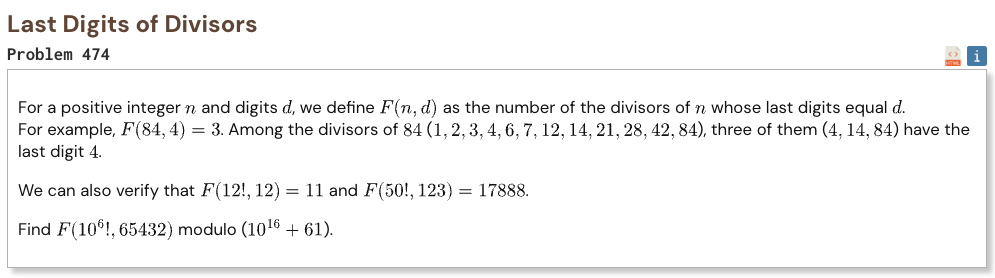

## Initial approach

- a divisor ending in 65432 must contain exactly three factors of 2 and no factors of 5
- divide the required ending by 8 so the remaining part only needs to equal 8179 modulo 12500
- every other prime factor is coprime to 12500 so its residue belongs to a multiplicative group of 5000 elements
- represent each residue by its value modulo 4 and a discrete logarithm modulo 3125
- process the allowed exponent range of every prime in 10^6! with dynamic programming over those 5000 group states
- use cyclic sliding sums so a prime with a very large factorial exponent still costs only about 5000 operations
- use numpy for compact arrays and numba to compile the roughly 5000 state transitions efficiently
- keep every count modulo 10^16 + 61

In [1]:
%%time

import math
import numpy as np
from numba import njit

N = 1_000_000
MOD = 10**16 + 61
GROUP_SIZE = 5000
ORDER = 2500

def prime_sieve(n):
    sieve = bytearray(b"\x01") * (n + 1)
    sieve[0:2] = b"\x00\x00"

    for p in range(2, math.isqrt(n) + 1):
        if sieve[p]:
            start = p * p
            sieve[start:n + 1:p] = b"\x00" * (
                (n - start) // p + 1
            )

    return np.array(
        [p for p in range(2, n + 1) if sieve[p]],
        dtype=np.int32
    )

dlog = np.full(3125, -1, dtype=np.int32)

value = 1

for exponent in range(ORDER):
    dlog[value] = exponent
    value = value * 2 % 3125

target_log = int(dlog[8179 % 3125])
target_parity = 1
target_state = target_parity * ORDER + target_log

primes = prime_sieve(N)

@njit
def add_mod(a, b):
    value = a + b

    if value >= MOD:
        value -= MOD

    return value

@njit
def sub_mod(a, b):
    if a >= b:
        return a - b

    return a + MOD - b

@njit
def mul_small_mod(a, b):
    result = np.int64(0)
    value = a

    while b > 0:
        if b & 1:
            result = add_mod(result, value)

        value = add_mod(value, value)
        b >>= 1

    return result

@njit
def factorial_exponent(n, p):
    total = 0

    while n:
        n //= p
        total += n

    return total

@njit
def transition(dp, prime_parity, prime_log, exponent):
    new_dp = np.zeros(GROUP_SIZE, dtype=np.int64)
    visited = np.zeros(GROUP_SIZE, dtype=np.uint8)
    cycle = np.empty(GROUP_SIZE, dtype=np.int32)

    for start in range(GROUP_SIZE):
        if visited[start]:
            continue

        current = start
        length = 0

        while not visited[current]:
            visited[current] = 1
            cycle[length] = current
            length += 1

            parity = current // ORDER
            log_value = current % ORDER

            parity ^= prime_parity
            log_value += prime_log

            if log_value >= ORDER:
                log_value -= ORDER

            current = parity * ORDER + log_value

        width = exponent + 1
        full_cycles = width // length
        remainder = width % length

        cycle_sum = np.int64(0)

        for i in range(length):
            cycle_sum = add_mod(
                cycle_sum,
                dp[cycle[i]]
            )

        base = mul_small_mod(
            cycle_sum,
            full_cycles
        )

        if remainder == 0:
            for i in range(length):
                new_dp[cycle[i]] = base

            continue

        window = np.int64(0)

        for offset in range(remainder):
            index = (-offset) % length
            window = add_mod(
                window,
                dp[cycle[index]]
            )

        new_dp[cycle[0]] = add_mod(
            base,
            window
        )

        for i in range(1, length):
            incoming = dp[cycle[i]]
            outgoing_index = (
                i - remainder
            ) % length
            outgoing = dp[
                cycle[outgoing_index]
            ]

            window = add_mod(
                window,
                incoming
            )
            window = sub_mod(
                window,
                outgoing
            )

            new_dp[cycle[i]] = add_mod(
                base,
                window
            )

    return new_dp

@njit
def solve(n, primes, dlog, target_state):
    dp = np.zeros(GROUP_SIZE, dtype=np.int64)
    dp[0] = 1

    for p in primes:
        if p == 2 or p == 5:
            continue

        exponent = factorial_exponent(
            n,
            int(p)
        )

        parity = 0 if p % 4 == 1 else 1
        log_value = int(
            dlog[p % 3125]
        )

        dp = transition(
            dp,
            parity,
            log_value,
            exponent
        )

    return dp[target_state]

result = solve(
    N,
    primes,
    dlog,
    target_state
)

print("Result:", result)

Result: 9690646731515010
CPU times: user 4.31 s, sys: 162 ms, total: 4.47 s
Wall time: 5.01 s
